# Домашняя работа 1
## В данном задании мы будем сжимать звуковую дорожку при помощи алгоритма PCA

In [ ]:
# Понадобится для чтения и записи аудио файлов
from scipy.io import wavfile

# Это нужно для проигрывания аудио файлов прямо в блокноте
from IPython.display import Audio

# А это набор для этого задания
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import seaborn as sns

In [ ]:
# Скачаем данные
! wget https://www.dropbox.com/s/p5147nr8mzemxnr/Beethoven_Violin_Sonata_Op_96_first_movement_bars_1-22.wav

--2022-12-14 11:37:57--  https://www.dropbox.com/s/p5147nr8mzemxnr/Beethoven_Violin_Sonata_Op_96_first_movement_bars_1-22.wav
Resolving www.dropbox.com (www.dropbox.com)... 162.125.65.18, 2620:100:6021:18::a27d:4112
Connecting to www.dropbox.com (www.dropbox.com)|162.125.65.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: /s/raw/p5147nr8mzemxnr/Beethoven_Violin_Sonata_Op_96_first_movement_bars_1-22.wav [following]
--2022-12-14 11:37:57--  https://www.dropbox.com/s/raw/p5147nr8mzemxnr/Beethoven_Violin_Sonata_Op_96_first_movement_bars_1-22.wav
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://ucef0053f5b0fa3d4de9bf652ead.dl.dropboxusercontent.com/cd/0/inline/Byn1WBWTqXXboFLsqpNAjSIqo1BviKmOF8QPB7T4K4WdkoWcV1qGWFtPNs1PTcRTNtvgonw2Jm8yJeCNu-2ysgeLvw5syH3NT2Z0GYXjzoM7mJDPB6qKeCqWOcOs7cpQahjrxfwepeTRVz02CZY6UDwEOu5gu2wcefLUKERcKRYYGg/file# [following]
--2022-12-14 11:37:58--  https://ucef00

In [ ]:
# Прочитаем аудио дорожку при помощи wavfile
samplerate, data = wavfile.read('Beethoven_Violin_Sonata_Op_96_first_movement_bars_1-22.wav')

`samplerate` есть частота дискретизации - стандартное для аудио значение -- 44100 Гц.

NOTE: **Частота дискретизации** говорит о том, сколько последовательных элементов массива с сигналом кодируют звук длительностью 1 секунда

In [ ]:
# Посмотрим какая у нас частота дискретизации
print(samplerate)

44100


In [ ]:
# Если поделить длину массива сигнала на samplerate, получится длительность аудиодорожки в секундах

print(len(data) / samplerate)

# 45 секунд - похоже на правду:)

45.139591836734695


In [ ]:
# Заметим, что звук - стерео, так как сигнал кодируется двумя каналами (для левого и правого динамика):

print(data.shape)

(1990656, 2)


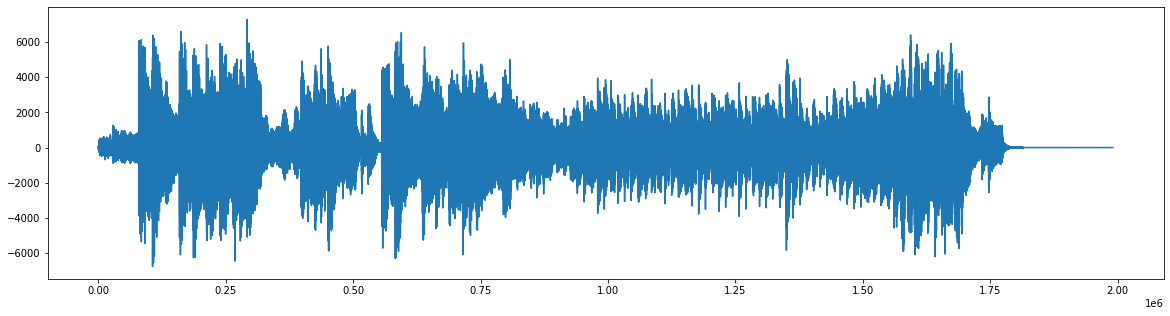

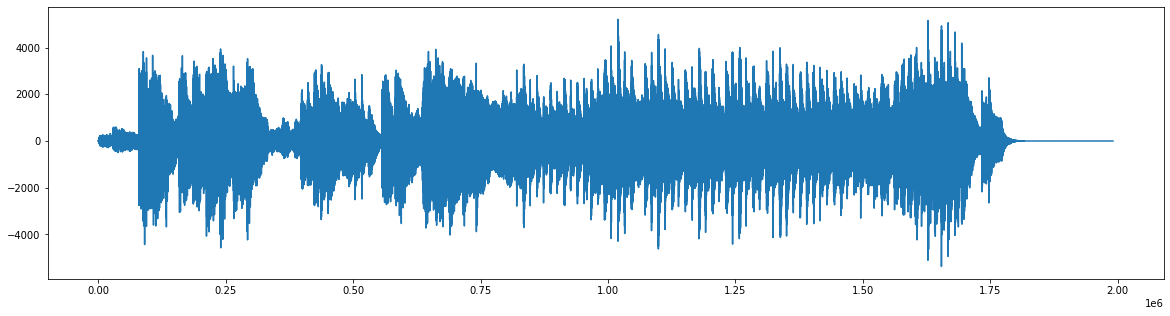

In [ ]:
# Отрисуем сигналы в обоих каналах

# Канал 1
plt.figure(figsize=(20,5))
plt.plot(data[:,0])
plt.show()

# Канал 2
plt.figure(figsize=(20,5))
plt.plot(data[:,1])
plt.show()

In [ ]:
# Усредним каналы, и получим моно звук, с которым будет проще работать

mono_sound = np.mean(data, axis=1)
print(mono_sound.shape)

(1990656,)


In [ ]:
# Давайте послушаем наконец, что же мы будем сжимать:)

Audio(mono_sound, rate = samplerate)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# Для удобства - обрежем массив с сигналом так, чтобы его было удобнее делить на равные части, датасет из которых и необходимо будет сжать известными вам методами.

mono_sound_to_cut = mono_sound[:1990000]

In [ ]:
# Проверим, что наш звук теперь это просто вектор чисел

print(mono_sound_to_cut.shape)

(1990000,)


#### Задание 1:

**Подсказка:** В этом задании нужно воспользоваться методом `.reshape()`


1. Разделим сигнал на равные части (длину каждой части возьмём равной 1000) и соберём из них "датасет", который будет представлять из себя двухмерный массив - "матрицу", в которой каждая часть сигнала длины 1000 находится в отдельной строке.

    То есть первая часть содержит первые 1000 чисел сигнала и находится в первой строке матрицы, вторая часть следующие 1000 чисел сигнала и находится во второй строке матрицы и так далее.

In [ ]:
# решение
mono_sound_to_cut.reshape((1990, 1000))\
.shape

(1990, 1000)

In [ ]:
print(mono_sound_to_cut.reshape((1990, 1000)))

[[  0.   -1.   -1.  ...  88.5  58.5  18. ]
 [-25.5 -61.5 -81.5 ...  30.5 -20.5 -53. ]
 [-67.5 -65.5 -50.  ... 118.5 118.5  86.5]
 ...
 [  0.    0.    0.  ...   0.    0.    0. ]
 [  0.    0.    0.  ...   0.    0.    0. ]
 [  0.    0.    0.  ...   0.    0.    0. ]]


2. Напишем функцию, которая будет переводить нашу "матрицу" обратно в звуковой сигнал, то есть разворачивать данные обратно из матрицы размера `(число объектов, 1000)` в вектор длины `(число объектов * 1000)`. Проверим, что все работает верно, путем воспроизведения "востановленного" сигнала -- он должен совпасть в точности с изначальным.

In [ ]:
mono_sound_to_cut.reshape((1990*1000))\
.shape

(1990000,)

In [ ]:
Audio(mono_sound_to_cut, rate = samplerate)

Output hidden; open in https://colab.research.google.com to view.

#### Задание 2

1. Выполните PCA преобразование нашей матрицы, и получите данные, сжатые в пространство меньшей размерности.

    На этом этапе у нас есть наш "датасет" с 1000 "признаками" и мы хотим уменьшить число "признаков" путем применения метода PCA. Число компонентов не стоит брать слишком маленькое, чтобы потом было проще понять, в случае плохого результата -- компонент оказалось недостаточно или мы где-то ошиблись:)


In [ ]:
pca = PCA(n_components = 500)

In [ ]:
X = mono_sound_to_cut.reshape((1990, 1000))

In [ ]:
Y = pca.fit_transform(X)

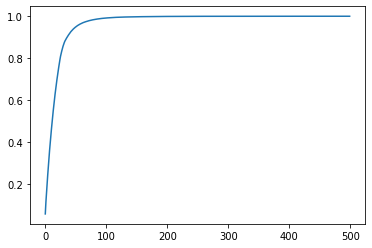

In [ ]:
cumsum = np.cumsum(pca.explained_variance_ratio_)
plt.plot(cumsum)

In [ ]:
d = np.argmax(cumsum >= 0.97) + 1
d

64

In [ ]:
Y.shape

(1990, 52)


2. Постройте сами две главные компоненты в наглядной форме. Сделайте выводы исходя из их вида.

    То есть необходимо применить метод PCA к нашей матрице с числом компонент, равным 2 (тем самым получив датасет с 2 "признаками"). Это позволит нам отрисовать данные на плоскости, чтобы попытаться уловить зависимости.

In [ ]:
pca = PCA(n_components = 2)
Y = pca.fit_transform(X)
Y.shape

(1990, 2)

In [ ]:
pca.components_

array([[ 0.01617006,  0.01762409,  0.01915782, ...,  0.01581794,
         0.01414535,  0.01255018],
       [-0.05183889, -0.05332339, -0.05476284, ...,  0.0541581 ,
         0.05236807,  0.0505674 ]])

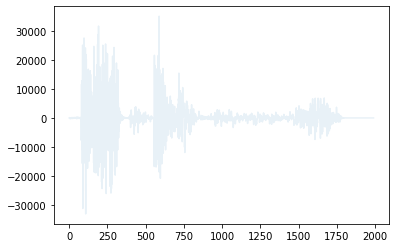

In [ ]:
plt.plot(Y[:, 0], alpha=0.1)

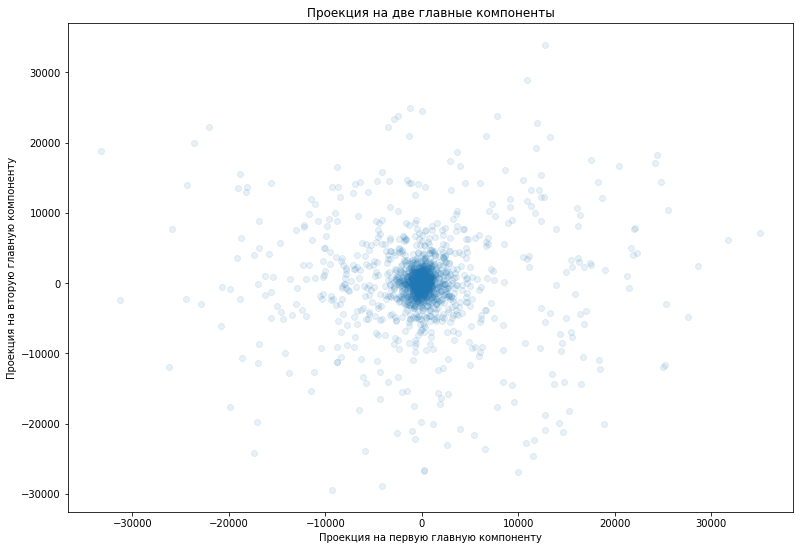

In [ ]:
plt.figure(figsize=(13, 9))
plt.scatter(Y[:, 0], Y[:, 1], alpha=0.1)
plt.xlabel('Проекция на первую главную компоненту')
plt.ylabel('Проекция на вторую главную компоненту')
plt.title('Проекция на две главные компоненты')
plt.show()

3. Постройте scatter plot датасета в пространстве первых двух компонент, а третью используйте как цвет.
    То есть необходимо применить метод PCA уже с 3 компонентами и нарисовать опять точки, только передав третью компоненту в качестве цвета.

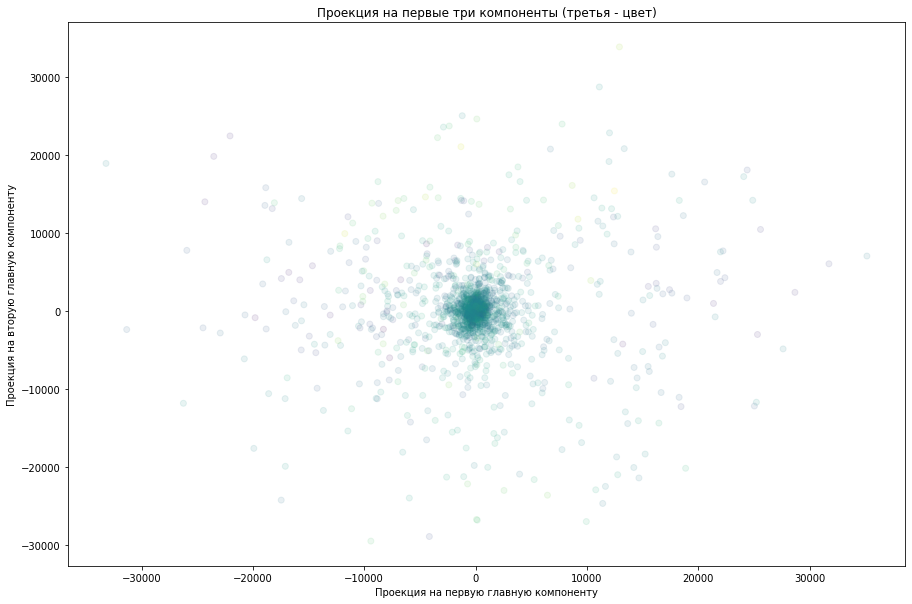

In [ ]:
pca = PCA(n_components=3)
Y = pca.fit_transform(X)
plt.figure(figsize=(15, 10))
plt.scatter(Y[:, 0], Y[:, 1], c=Y[:, 2], alpha=0.1)
plt.xlabel('Проекция на первую главную компоненту')
plt.ylabel('Проекция на вторую главную компоненту')
plt.title('Проекция на первые три компоненты (третья - цвет)')
plt.show()

#### Задание 3

Нам осталось заняться непосредственно "сжатием" звука и проверкой правильности наших действий.

1. Выполните обратное PCA преобразование сжатых данных и получите "матрицу" со сжатым звуком.

    Воспользуйтесь обратным преобразованием PCA (inverse_transform), чтобы из матрицы размера `(число объектов, число компонент)` перейти в матрицу размера `(число объектов, 1000)`.

In [ ]:
X_hat = pca.inverse_transform(Y)

In [ ]:

pca = PCA(n_components = 500)
Y = pca.fit_transform(X)

In [ ]:
print(X.shape)
print(Y.shape)
print(X_hat.shape)

(1990, 1000)
(1990, 500)
(1990, 1000)


In [ ]:
X_hat = pca.inverse_transform(Y)
X_hat.shape

(1990, 1000)

2. Преобразуйте "матрицу", получившуюся обратным преобразованием, в сигнал (одномерный массив, наш "сжатый" монозвук), и послушайте результат `(Audio(YOUR_RESULT, rate = samplerate)`.

    Воспользуйтесь функцией, которую написали в первом задании, чтобы преобразовать матрицу со "сжатым" звуком (размер после обратного преобразования должен быть такой же, как и у оригинальной матрицы) в вектор-сигнал, который уже можно будет прослушать. Если звук похож на оригинал, то вы все сделали правильно! 

In [ ]:
X_orig = X_hat.reshape((1990*1000))
Audio(X_orig, rate = samplerate)

Output hidden; open in https://colab.research.google.com to view.

3. Исследуйте зависимость качества звука от числа компонент. Подберите "на слух" минимальное число компонент, при котором звук практически не отличается от оригинала.

    Добавьте в ячейки два варианта звуковой дорожки -- оригинальную и выбранную вами. Укажите какое число компонент вы оставили.

Подсказка! попробуйте отфильтровать сигнал с помощью функции `gaussian_filter1d` из `scipy.ndimage`. Это поможет убрать неприятный дробовой шум при сильном сжатии

Пример кода для фильтрации - `Audio(gaussian_filter1d(mono_sound_compressed, 2), rate = samplerate)`

In [ ]:
from scipy.ndimage import gaussian_filter1d

In [ ]:
pca = PCA(n_components = 64)
Y = pca.fit_transform(X)
Y.shape

(1990, 64)

In [ ]:
X_hat = pca.inverse_transform(Y)
X_hat.shape

(1990, 1000)

In [ ]:
X_orig = X_hat.reshape((1990*1000))
Audio(X_orig, rate = samplerate)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
X_orig = X_hat.reshape((1990*1000))
Audio(gaussian_filter1d(X_orig, 2), rate = samplerate)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
Audio(mono_sound, rate = samplerate)

Output hidden; open in https://colab.research.google.com to view.


3.1   Ответьте на вопросы: 
- Количество компонент, которое вы выбрали это много или мало? 
- Как сильно можно сжать звук таким образом? 
- А если нам дадут другую звуковую дорожку, нам надо сделать то же самое, чтобы сжать звук, как автоматически подобрать число компонент и возможно ли это?




У меня получилось 64 компонента и это уже не очень сильно сказывается на конечном результате. 64 - это мало, по сравнению с изначальной 1000. Но оригинальная мелодия ещё слышна хорошо, только присутствует шум. Сжатие получилось 15-кратным.
Постаралась найти автоматически количество компонентов с помощью графика и формулы кумулятивной дисперсии, поставив 97% уникальных признаков (компонентов)

4. (доп задание)

  a) Оберните получившийся код по сжатию звука в одну или несколько функций

  b) Проведите исследование того, как степень сжатия (соотношения размера частей, на которые делился сигнал в задании 1.1 к размеру пространсва, в которое вы сжимали данные с помощью PCA) влияет на звук, по субъективным ощущениям. Начиная с какой степени сжания сильно слышится потеря качества? (как с учетом фильтрации с помощью gaussian_filter1d, так и без неё)

  d) Что степень сжатия означает для PCA? Для большой аудиозаписи (3 мин, например) мы хотели бы разбить на большее, меньшее или такое же число отрезков как и для предложенной аудиозаписи? Почему?

  c) Можно ли как-то автоматически подобрать степерь сжатия? За что она отвечает в нашей задаче. Как степень сжатия влияет на звук? Почему она так влияет на звук? 



In [ ]:
# задание

In [71]:
def compr_music(X, n_1, visualization = 'True'): # X - наш монозвуковой файл
  from sklearn.decomposition import PCA
  pca = PCA(n_components = n_1)
  X = X.reshape((1990, 1000))
  Z = pca.fit_transform(X)

  cumsum = np.cumsum(pca.explained_variance_ratio_)
  d = np.argmax(cumsum >= 0.97) + 1
  
  print(Z.shape)
  if d > 1:
    print('Автоматически вычисленное количество компонентов')
    print('=', d)
  else:
    print('Автоматически вычисленное количество компонентов больше выбранного')
  Z_orig = pca.inverse_transform(Z)
  Z1 = Z_orig.reshape((1990*1000))

  from scipy.ndimage import gaussian_filter1d

  %matplotlib inline
  green = '#00CC66'

  if visualization == 'True':
    pca1 = PCA(n_components = 2)
    Z2 = pca1.fit_transform(X)
    plt.figure(figsize=(13, 9))
    plt.scatter(Z2[:, 0], Z2[:, 1], alpha=0.1, color = green)    
    plt.xlabel('Исходный признак 1')
    plt.ylabel('Исходный признак 2')
    plt.title('Проекция на две главные компоненты')
    plt.show()

    plt.plot(Z2[:, 0])
    plt.plot(Z2[:, 1])
    plt.show
 
  return Audio(gaussian_filter1d(Z1, 2), rate = samplerate)

In [72]:
compr_music(mono_sound_to_cut, 500, visualization = 'False')

Output hidden; open in https://colab.research.google.com to view.

In [73]:
compr_music(mono_sound_to_cut, 100, visualization = 'True')

Output hidden; open in https://colab.research.google.com to view.

In [64]:
compr_music(mono_sound_to_cut, 80, visualization = 'True')

Output hidden; open in https://colab.research.google.com to view.

In [74]:
compr_music(mono_sound_to_cut, 60, visualization = 'False')

Output hidden; open in https://colab.research.google.com to view.

Выводы:
PCA используется для сжатия данных, до определённого количества оставшихся компонентов сжатый файл не сильно отличается от исходного. Автоматически график кумулятивной дисперсии показывает количество уникальных признаков датасета, и позволяет нам отбрасывая большинство сходных между собой признаков сжать наши данные без больших потерь. Но всё равно, качество восстановленного файла можно оценить только исходя из конкретной поставленной задачи.
Если исходным будет файл длиннее по времени, то я думаю, его можно разделить на такое же количество отрезков, ведь потом сработает PCA и метод кумулятивной дисперсии.
Степень сжатия влияет на чистоту звука, отсутствие шума. Причина этого - разделение звучания в оригинале (мои догадки), тогда как сжатие удаляет "межпространство"